In [ ]:
import pandas as pd, glob, re

months = ["JANUARY","FEBRUARY","MARCH","APRIL","MAY","JUNE","JULY",
          "AUGUST","SEPTEMBER","OCTOBER","NOVEMBER","DECEMBER"]

paths = sorted(glob.glob("*gas-production-status-report*"))
print("Files found:", paths)

frames = []
for path in paths:
    year = int(re.search(r"(20\d\d)", path).group(1))
    raw = pd.read_excel(path, header=None)

    # find the row that has the word MONTHS (the header row)
    is_hdr = raw.apply(lambda r: r.astype(str).str.strip().str.upper().eq("MONTHS").any(), axis=1)
    hdr = raw.index[is_hdr][0]

    df = raw.iloc[hdr + 1:].copy()
    df.columns = raw.iloc[hdr].astype(str).str.strip()
    df = df.dropna(axis=1, how="all")

    # keep only the 12 month rows (drops TOTAL and the note)
    df = df[df["MONTHS"].astype(str).str.strip().str.upper().isin(months)]
    df["year"] = year
    frames.append(df)
    print(year, "columns:", list(df.columns), "rows:", len(df))

data = pd.concat(frames, ignore_index=True)
print(data.head())

Files found: ['gas-production-status-report_2021_Production_data_excel_1781450458502.xlsx', 'gas-production-status-report_2022_Production_data_excel_1781450455089.xlsx', 'gas-production-status-report_2023_Production_data_excel_1781450451939.xlsx', 'gas-production-status-report_2024_Production_data_excel_1781450447950.xlsx']
2021 columns: ['MONTHS', 'AG PRODUCTION (MMSCF)', 'NAG PRODUCTION (MMSCF)', 'TOTAL GAS PRODUCTION (MMSCF)', 'FIELD USE (MMSCF)', 'DOMESTIC SALES (MMSCF)', 'EXPORT SALES (MMSCF)', 'TOTAL GAS UTILISED (MMSCF)', '% UTILIZED', 'TOTAL GAS FLARED (MMSCF)', '% FLARED', 'GAS SHRINKAGE', 'year'] rows: 12
2022 columns: ['MONTHS', 'AG PRODUCTION (MMSCF)', 'NAG PRODUCTION (MMSCF)', 'TOTAL GAS PRODUCTION (MMSCF)', 'FIELD USE (MMSCF)', 'DOMESTIC SALES (MMSCF)', 'EXPORT SALES (MMSCF)', 'TOTAL GAS UTILISED (MMSCF)', '% UTILIZED', 'TOTAL GAS FLARED (MMSCF)', '% FLARED', 'GAS SHRINKAGE', 'year'] rows: 12
2023 columns: ['MONTHS', 'AG PRODUCTION (MMSCF)', 'NAG PRODUCTION (MMSCF)', 'TOT

In [ ]:
# 1. Turn the columns into proper numbers
num_cols = [c for c in data.columns if c not in ["MONTHS", "year"]]
for c in num_cols:
    data[c] = pd.to_numeric(data[c], errors="coerce")

# 2. Give the columns short names
data = data.rename(columns={
    "AG PRODUCTION (MMSCF)": "ag",
    "NAG PRODUCTION (MMSCF)": "nag",
    "TOTAL GAS PRODUCTION (MMSCF)": "total",
    "FIELD USE (MMSCF)": "field_use",
    "DOMESTIC SALES (MMSCF)": "domestic",
    "EXPORT SALES (MMSCF)": "export",
    "TOTAL GAS UTILISED (MMSCF)": "utilised",
    "TOTAL GAS FLARED (MMSCF)": "flared",
    "GAS SHRINKAGE": "shrinkage",
})

# 3. Make a proper date column
month_num = {m: i + 1 for i, m in enumerate(months)}
data["month"] = data["MONTHS"].str.strip().str.upper().map(month_num)
data["date"] = pd.to_datetime(dict(year=data["year"], month=data["month"], day=1))
data["days"] = data["date"].dt.days_in_month

# 4. Drop the old % columns and the text month, then sort
data = data.drop(columns=["% UTILIZED", "% FLARED", "MONTHS"])
data = data.sort_values("date").reset_index(drop=True)

# 5. Data quality checks (do the numbers add up?)
data["gap_utilised"] = (data["field_use"] + data["domestic"] + data["export"] - data["utilised"]).abs()
data["gap_total"] = (data["utilised"] + data["flared"] + data["shrinkage"] - data["total"]).abs()
print("Biggest gap, utilised check:", round(data["gap_utilised"].max(), 2))
print("Biggest gap, total check:", round(data["gap_total"].max(), 2))

# 6. Our own percentages
data["flare_pct"] = data["flared"] / data["total"] * 100
data["domestic_share_pct"] = data["domestic"] / (data["domestic"] + data["export"]) * 100

# 7. Per-day figures, so short months don't look like drops
for c in ["total", "domestic", "export", "flared", "field_use"]:
    data[c + "_per_day"] = data[c] / data["days"]

print(data[["date", "total", "domestic", "total_per_day", "domestic_share_pct", "flare_pct"]].head(12))
print("Rows:", len(data), "| Missing values:", int(data.isna().sum().sum()))

# 8. Save it
data.to_csv("gas_monthly_clean.csv", index=False)

Biggest gap, utilised check: 0.0
Biggest gap, total check: 59.6
         date          total      domestic  total_per_day  domestic_share_pct  \
0  2021-01-01  236709.123735  49124.812422    7635.778185           31.388542   
1  2021-02-01  224188.086757  44977.983573    8006.717384           31.879684   
2  2021-03-01  235418.642071  45245.659311    7594.149744           31.415964   
3  2021-04-01  223392.356689  45506.069849    7446.411890           33.537153   
4  2021-05-01  233806.962649  54797.287690    7542.160085           37.809846   
5  2021-06-01  234489.412273  51279.009713    7816.313742           34.396828   
6  2021-07-01  241726.613716  51867.882967    7797.632701           34.374923   
7  2021-08-01  239970.229939  51046.852571    7740.975159           33.288766   
8  2021-09-01  221801.631405  45204.540275    7393.387714           32.945345   
9  2021-10-01  209112.291450  47496.759853    6745.557789           37.241506   
10 2021-11-01  215399.098611  46740.597702   

In [ ]:
import numpy as np

def flag_odd(series, window=6, cutoff=2.5):
    # typical level around each month (a rolling middle value)
    baseline = series.rolling(window, center=True, min_periods=3).median()
    diff = series - baseline
    # how big is a "normal" difference?
    spread = 1.4826 * (diff - diff.median()).abs().median()
    score = diff / spread
    return score, score.abs() > cutoff

measures = ["total_per_day", "domestic_per_day", "export_per_day", "flared_per_day"]

for m in measures:
    data[m + "_score"], data[m + "_odd"] = flag_odd(data[m])

odd_cols = [m + "_odd" for m in measures]
data["any_odd"] = data[odd_cols].any(axis=1)

# show the flagged months
shown = data[data["any_odd"]][["date"] + measures + odd_cols]
print(shown.round(1).to_string())
print("Months flagged:", int(data["any_odd"].sum()), "out of", len(data))

# which month had the biggest gap in the total check?
worst = data.loc[data["gap_total"].idxmax(), ["date", "gap_total"]]
print("Biggest total-check gap was in:", worst["date"].date(), "|", round(worst["gap_total"], 1))

data.to_csv("gas_monthly_clean.csv", index=False)

         date  total_per_day  domestic_per_day  export_per_day  flared_per_day  total_per_day_odd  domestic_per_day_odd  export_per_day_odd  flared_per_day_odd
9  2021-10-01         6745.6            1532.2          2581.9           612.8               True                 False                True               False
29 2023-06-01         6693.8            1532.0          2372.0           486.5              False                  True               False               False
34 2023-11-01         6547.8            1997.5          2004.4           542.4              False                  True               False               False
36 2024-01-01         7129.9            1590.7          2876.8           590.6              False                 False                True               False
37 2024-02-01         6635.5            1510.7          2568.5           541.0              False                  True               False               False
Months flagged: 5 out of 48
Biggest tota

In [ ]:
# Which direction was each flagged month? (negative = lower than neighbours)
for m in measures:
    print(m)
    print(data.loc[data[m + "_odd"], ["date", m, m + "_score"]].round(1).to_string())
    print()

# What did October 2022 look like?
print(data.loc[data["date"].between("2022-08-01", "2022-12-01"),
      ["date", "total_per_day", "export_per_day", "export_per_day_score"]].round(1).to_string())

total_per_day
        date  total_per_day  total_per_day_score
9 2021-10-01         6745.6                 -2.5

domestic_per_day
         date  domestic_per_day  domestic_per_day_score
29 2023-06-01            1532.0                    -3.0
34 2023-11-01            1997.5                     3.2
37 2024-02-01            1510.7                    -3.5

export_per_day
         date  export_per_day  export_per_day_score
9  2021-10-01          2581.9                  -2.9
36 2024-01-01          2876.8                   2.7

flared_per_day
Empty DataFrame
Columns: [date, flared_per_day, flared_per_day_score]
Index: []

         date  total_per_day  export_per_day  export_per_day_score
19 2022-08-01         6211.8          2191.2                  -2.1
20 2022-09-01         6509.9          2441.3                   0.1
21 2022-10-01         6476.5          2380.1                  -0.1
22 2022-11-01         6684.5          2409.3                   0.4
23 2022-12-01         6284.0          2286

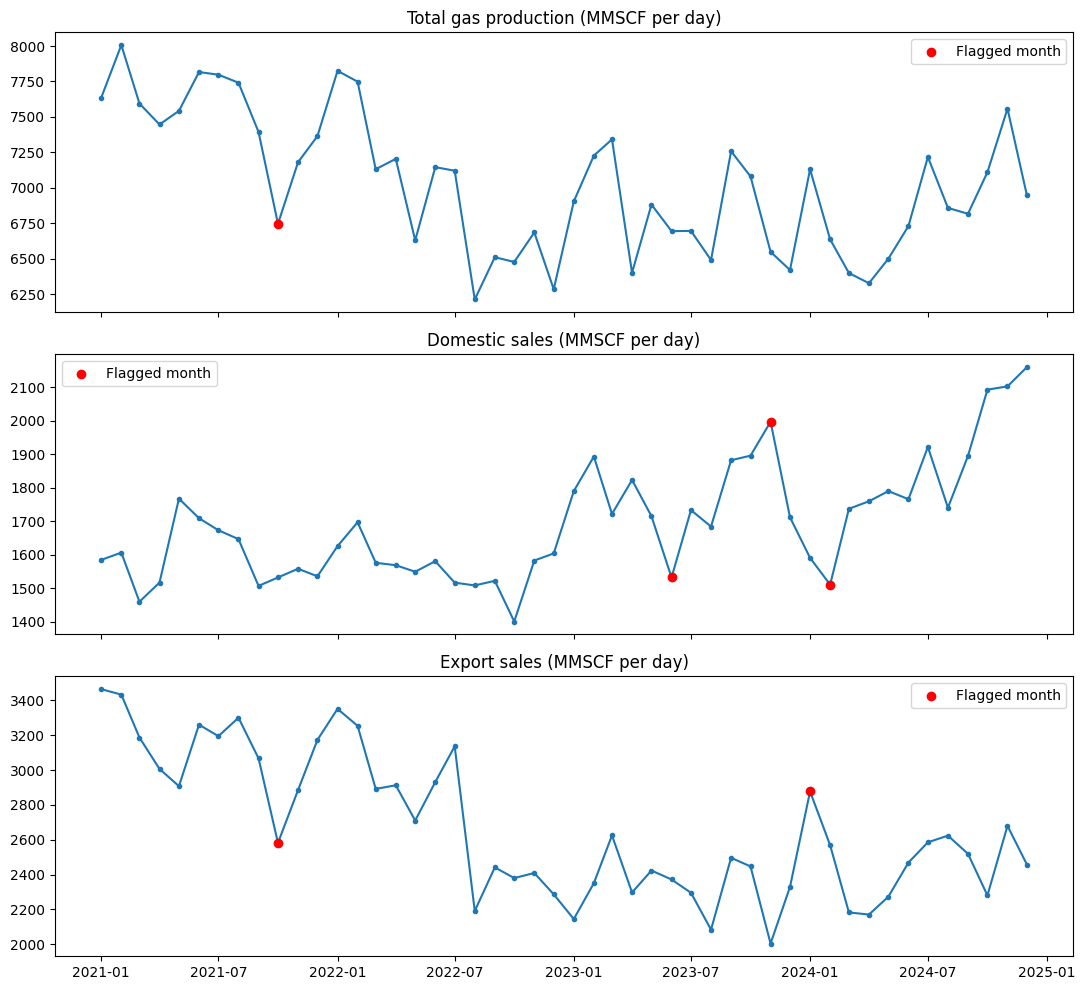

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, m, title in zip(axes,
        ["total_per_day", "domestic_per_day", "export_per_day"],
        ["Total gas production", "Domestic sales", "Export sales"]):
    ax.plot(data["date"], data[m], marker="o", markersize=3)
    odd = data[data[m + "_odd"]]
    ax.scatter(odd["date"], odd[m], color="red", zorder=5, label="Flagged month")
    ax.set_title(title + " (MMSCF per day)")
    ax.legend()
plt.tight_layout()
plt.savefig("flagged_months.png", dpi=150)
plt.show()

In [ ]:
import pandas as pd, numpy as np

# month, ag, nag, total, field_use, domestic, export, utilised, flared, shrinkage
rows_2025 = [
 (1, 128626.12, 107689.03, 236315.14, 69649.56, 64206.09, 83476.39, 217332.04, 18718.64, 264.46),
 (2, 114046.46, 85634.77, 199681.23, 66191.65, 58473.65, 58985.16, 183650.46, 15852.83, 177.95),
 (3, 127608.05, 103669.50, 231277.56, 68896.17, 64303.75, 81524.33, 214724.25, 16377.65, 175.66),
 (4, 127052.86, 105931.46, 232984.33, 67996.12, 70442.91, 77036.65, 215475.68, 17295.39, 213.26),
 (5, 133178.04, 111264.13, 244442.16, 73417.80, 72966.26, 80337.02, 226721.09, 17465.45, 255.63),
 (6, 128505.87, 110449.99, 238955.86, 73513.99, 69443.16, 78540.78, 221497.93, 17252.74, 205.19),
 (7, 138817.29, 112063.25, 250880.54, 71383.68, 70620.90, 90337.36, 232341.94, 18328.22, 210.38),
 (8, 130583.96, 96431.26, 227015.22, 72899.51, 71378.32, 65732.24, 210010.07, 16729.35, 275.79),
 (9, 124101.78, 74218.48, 198320.26, 70185.57, 64560.55, 45434.99, 180181.11, 17952.52, 186.63),
 (10, 107130.45, 113923.76, 221054.21, 53590.78, 61893.38, 88735.33, 204219.49, 16699.77, 134.95),
 (11, 101193.82, 111328.55, 212522.37, 49735.25, 56240.13, 90689.96, 196665.34, 15846.89, 10.14),
 (12, 95165.21, 117399.73, 212564.95, 39110.56, 56085.69, 101913.03, 197109.28, 15445.19, 10.49),
]

base = ["date","year","month","ag","nag","total","field_use","domestic","export","utilised","flared","shrinkage"]

old = data[base].copy()
old["provisional"] = False

new = pd.DataFrame(rows_2025, columns=["month","ag","nag","total","field_use","domestic","export","utilised","flared","shrinkage"])
new["year"] = 2025
new["date"] = pd.to_datetime(dict(year=new["year"], month=new["month"], day=1))
new["provisional"] = new["month"] >= 10

data = pd.concat([old, new[old.columns]], ignore_index=True).sort_values("date").reset_index(drop=True)

# rebuild everything on the full 60 months
data["days"] = data["date"].dt.days_in_month
data["gap_utilised"] = (data["field_use"] + data["domestic"] + data["export"] - data["utilised"]).abs()
data["gap_total"] = (data["utilised"] + data["flared"] + data["shrinkage"] - data["total"]).abs()
data["flare_pct"] = data["flared"] / data["total"] * 100
data["domestic_share_pct"] = data["domestic"] / (data["domestic"] + data["export"]) * 100
for c in ["total", "domestic", "export", "flared", "field_use"]:
    data[c + "_per_day"] = data[c] / data["days"]

def flag_odd(series, window=6, cutoff=2.5):
    baseline = series.rolling(window, center=True, min_periods=3).median()
    diff = series - baseline
    spread = 1.4826 * (diff - diff.median()).abs().median()
    score = diff / spread
    return score, score.abs() > cutoff

measures = ["total_per_day", "domestic_per_day", "export_per_day", "flared_per_day"]
for m in measures:
    data[m + "_score"], data[m + "_odd"] = flag_odd(data[m])
data["any_odd"] = data[[m + "_odd" for m in measures]].any(axis=1)

print("Rows:", len(data), "| Missing:", int(data.isna().sum().sum()))
print("Biggest gap, utilised check:", round(data["gap_utilised"].max(), 2))
print("Biggest gap, total check:", round(data["gap_total"].max(), 2))

print("\nFlagged months:")
for m in measures:
    f = data.loc[data[m + "_odd"], ["date", m, m + "_score", "provisional"]]
    if len(f):
        print(m); print(f.round(1).to_string()); print()
print("Total flagged:", int(data["any_odd"].sum()), "of", len(data))

yearly = data.groupby("year")[["total", "domestic", "export", "flared"]].sum()
yearly["domestic_share_pct"] = yearly["domestic"] / (yearly["domestic"] + yearly["export"]) * 100
yearly["flare_pct"] = yearly["flared"] / yearly["total"] * 100
print("\nYearly summary:")
print(yearly.round(1))

data.to_csv("gas_monthly_clean.csv", index=False)

Rows: 60 | Missing: 0
Biggest gap, utilised check: 0.01
Biggest gap, total check: 59.6

Flagged months:
total_per_day
        date  total_per_day  total_per_day_score  provisional
9 2021-10-01         6745.6                 -2.5        False

domestic_per_day
         date  domestic_per_day  domestic_per_day_score  provisional
29 2023-06-01            1532.0                    -2.8        False
34 2023-11-01            1997.5                     3.0        False
37 2024-02-01            1510.7                    -3.2        False

export_per_day
         date  export_per_day  export_per_day_score  provisional
9  2021-10-01          2581.9                  -2.9        False
36 2024-01-01          2876.8                   2.7        False
49 2025-02-01          2106.6                  -2.7        False
55 2025-08-01          2120.4                  -2.6        False
56 2025-09-01          1514.5                  -6.7        False

Total flagged: 8 of 60

Yearly summary:
          total  